# Projeto Final - Entrega 2 (Dados Prontos)
## Meu Jogo É Baum?

---

**Machine Learning**

Tecnologia em Análise e Desenvolvimento de Sistemas

Instituto Federal de Mato Grosso do Sul - Câmpus Três Lagoas

Prof. Carlos R Santos Jr

**Integrantes:** Kenzo Senna, Hudson Batista Brandão, Matheus Felipe

---

## Preparação da base e função `limpar(df)`

Leitura da base de dados da Steam, aplicando os filtros definidos na Entrega 1 (remover jogos com `Estimated owners = "0 - 0"` e jogos lançados nos últimos 12 meses) e a função `limpar(df)` antes de separar treino e teste.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('data/games.csv.gz')
print('Tamanho original:', df.shape)

# Filtros da Entrega 1
datas_brutas = pd.to_datetime(df['Release date'], format='mixed', errors='coerce')
df = df[(df['Estimated owners'] != '0 - 0') & (df['Estimated owners'].notna()) & (datas_brutas < '2025-12-01')].copy()
print('Tamanho após filtros da E1:', df.shape)

Tamanho original: (125855, 40)
Tamanho após filtros da E1: (100292, 40)


In [2]:
def limpar(df):
    df = df.copy()
    df = df.drop_duplicates()

    # removendo colunas de ID, texto livre e colunas que só existem pós-lançamento (vazam o alvo)
    colunas_remover = [
        'AppID', 'Name', 'About the game', 'Reviews', 'Header image',
        'Website', 'Support url', 'Support email', 'Metacritic url',
        'Notes', 'Developers', 'Publishers', 'Screenshots', 'Movies',
        'Full audio languages', 'Discount', 'DLC count',
        'Positive', 'Negative', 'Recommendations', 'Peak CCU',
        'User score', 'Metacritic score', 'Score rank',
        'Average playtime forever', 'Average playtime two weeks',
        'Median playtime forever', 'Median playtime two weeks'
    ]
    df = df.drop(columns=colunas_remover, errors='ignore')

    # extraindo o mês de lançamento da data
    datas = pd.to_datetime(df['Release date'], format='mixed', errors='coerce')
    df['Release date'] = datas.dt.month

    # '[]' em Supported languages é ausente disfarçado -> vira NaN, depois contamos a qtd de idiomas
    df['Supported languages'] = df['Supported languages'].replace('[]', np.nan)
    df['Supported languages'] = df['Supported languages'].str.split(',').str.len()

    # pegando o gênero, categoria e tag principal de cada jogo
    df['Genres'] = df['Genres'].str.split(',').str[0].str.strip()
    df['Categories'] = df['Categories'].str.split(',').str[0].str.strip()
    df['Tags'] = df['Tags'].str.split(',').str[0].str.strip()

    # padronizando plataformas como texto
    df['Windows'] = df['Windows'].astype(str)
    df['Mac'] = df['Mac'].astype(str)
    df['Linux'] = df['Linux'].astype(str)

    # limites de domínio: preços acima de 200 dólares e conquistas acima de 500 (jogos spam) viram NaN
    df.loc[(df['Price'] < 0) | (df['Price'] > 200), 'Price'] = np.nan
    df.loc[(df['Achievements'] < 0) | (df['Achievements'] > 500), 'Achievements'] = np.nan

    # agrupando idade mínima em faixas ordinais
    df['Required age'] = pd.cut(
        df['Required age'],
        bins=[-1, 0, 12, 15, 17, 100],
        labels=['Livre', '10+', '13+', '16+', '18+']
    ).astype(object)

    return df

df_limpo = limpar(df)

# agrupando o alvo nas 3 classes definidas no README
mapa_alvo = {
    '0 - 20000': 'baixa',
    '20000 - 50000': 'media',
    '50000 - 100000': 'media',
    '100000 - 200000': 'media'
}
y = df_limpo['Estimated owners'].map(lambda x: mapa_alvo.get(x, 'alta'))
X = df_limpo.drop(columns=['Estimated owners'])

# divisão 80/20 estratificada igual na E1 (X_te fica guardado até a Entrega 3)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Treino:', X_tr.shape, '| Teste:', X_te.shape)
X_tr.head()

Treino: (80233, 11) | Teste: (20059, 11)


,Release date,Required age,Price,Supported languages,Windows,Mac,Linux,Achievements,Categories,Genres,Tags
41680,4,Livre,5.99,1.0,True,False,False,25.0,Single-player,Action,Trading
115218,2,Livre,1.99,4.0,True,False,False,0.0,Single-player,RPG,Strategy
22052,10,Livre,8.99,2.0,True,False,False,0.0,Single-player,Action,Action
32202,12,Livre,3.49,1.0,True,False,False,0.0,Single-player,Action,Horror
17067,4,Livre,15.99,10.0,True,True,False,0.0,Single-player,Indie,RPG


## 1. Como o alvo se distribui?

Estimated owners
baixa    59790
media    16157
alta      4286
Name: count, dtype: int64

Proporção (%):
Estimated owners
baixa    74.52
media    20.14
alta      5.34
Name: proportion, dtype: float64


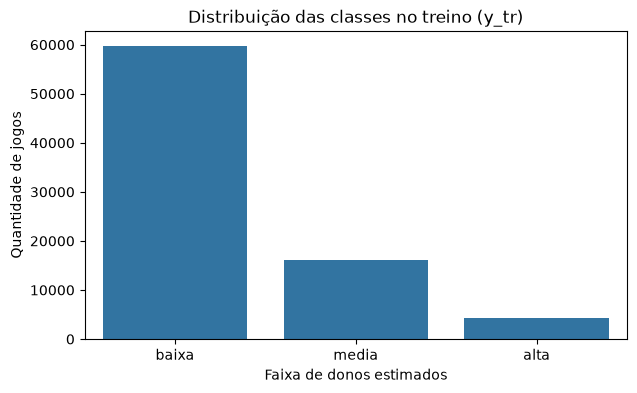

In [3]:
print(y_tr.value_counts())
print('\nProporção (%):')
print((y_tr.value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 4))
sns.countplot(x=y_tr, order=['baixa', 'media', 'alta'])
plt.title('Distribuição das classes no treino (y_tr)')
plt.xlabel('Faixa de donos estimados')
plt.ylabel('Quantidade de jogos')
plt.show()

**Observação:** O alvo é bem desbalanceado no treino: 74,52% dos jogos são da classe `baixa`, 20,14% da `media` e apenas 5,34% da `alta`.
**Decisão:** Manter o `stratify=y` no split e a métrica `f1_macro` escolhida na Entrega 1 (já que acurácia engana nesse cenário), e testar `class_weight="balanced"` na Entrega 3.

## 2. Onde faltam dados?

Tags                   16.94
Categories              0.82
Achievements            0.21
Genres                  0.13
Supported languages     0.09
Price                   0.01
Release date            0.00
Required age            0.00
Linux                   0.00
Windows                 0.00
Mac                     0.00
dtype: float64


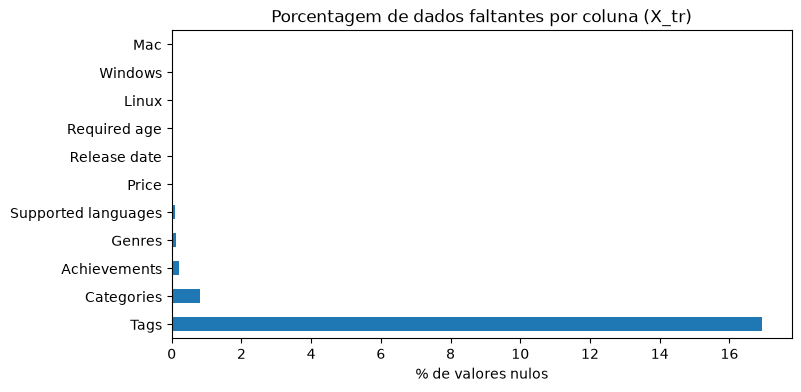

In [4]:
faltantes = (X_tr.isna().mean() * 100).sort_values(ascending=False).round(2)
print(faltantes)

plt.figure(figsize=(8, 4))
faltantes.plot(kind='barh')
plt.title('Porcentagem de dados faltantes por coluna (X_tr)')
plt.xlabel('% de valores nulos')
plt.show()

**Observação:** A coluna `Tags` tem 16,94% de valores vazios (entre 5% e 50%). As colunas `Categories` (0,82%), `Achievements` (0,21%), `Genres` (0,13%), `Supported languages` (0,09%) e `Price` (0,01%) têm menos de 1% de vazios, e o restante não tem nulos.
**Decisão:** Não usar `dropna()`. Imputar as numéricas pela mediana (`SimpleImputer(strategy="median")`), as categóricas pela moda e usar `add_indicator=True` para marcar quando o campo veio vazio.

## 3. Como cada variável se distribui?

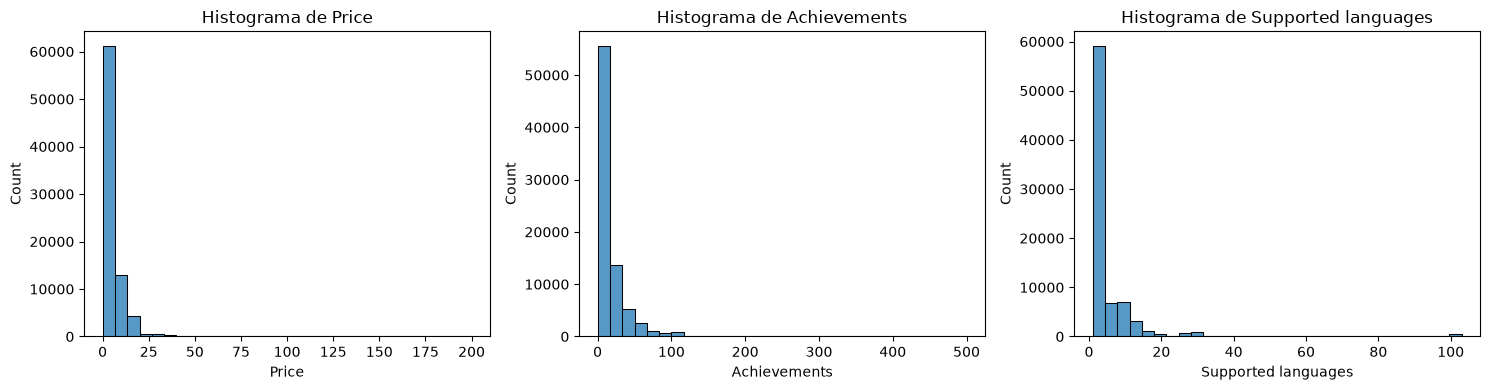

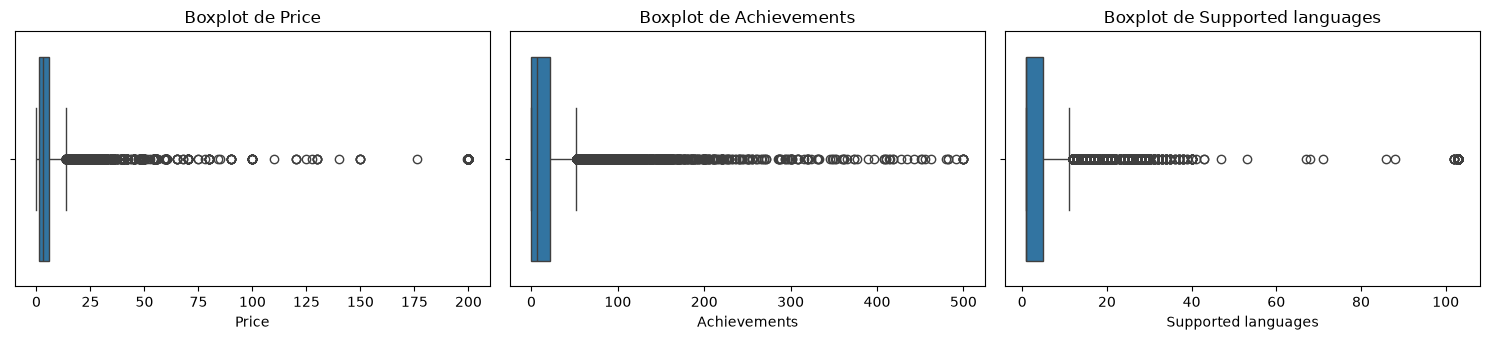

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(X_tr['Price'].dropna(), bins=30, ax=axes[0])
axes[0].set_title('Histograma de Price')

sns.histplot(X_tr['Achievements'].dropna(), bins=30, ax=axes[1])
axes[1].set_title('Histograma de Achievements')

sns.histplot(X_tr['Supported languages'].dropna(), bins=30, ax=axes[2])
axes[2].set_title('Histograma de Supported languages')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

sns.boxplot(x=X_tr['Price'], ax=axes[0])
axes[0].set_title('Boxplot de Price')

sns.boxplot(x=X_tr['Achievements'], ax=axes[1])
axes[1].set_title('Boxplot de Achievements')

sns.boxplot(x=X_tr['Supported languages'], ax=axes[2])
axes[2].set_title('Boxplot de Supported languages')

plt.tight_layout()
plt.show()

**Observação:** `Price` (mediana 2,99), `Achievements` (mediana 6) e `Supported languages` (mediana 1) são bastante assimétricas, com cauda longa à direita. Os erros/valores irreais (preços acima de 200 dólares e jogos spam com mais de 500 conquistas) já viraram `NaN` na função `limpar(df)`.
**Decisão:** Como a média é puxada pela cauda, usar `SimpleImputer(strategy="median")` + `StandardScaler()` no pipeline para as três colunas. Os valores altos restantes são de jogos reais e foram mantidos.

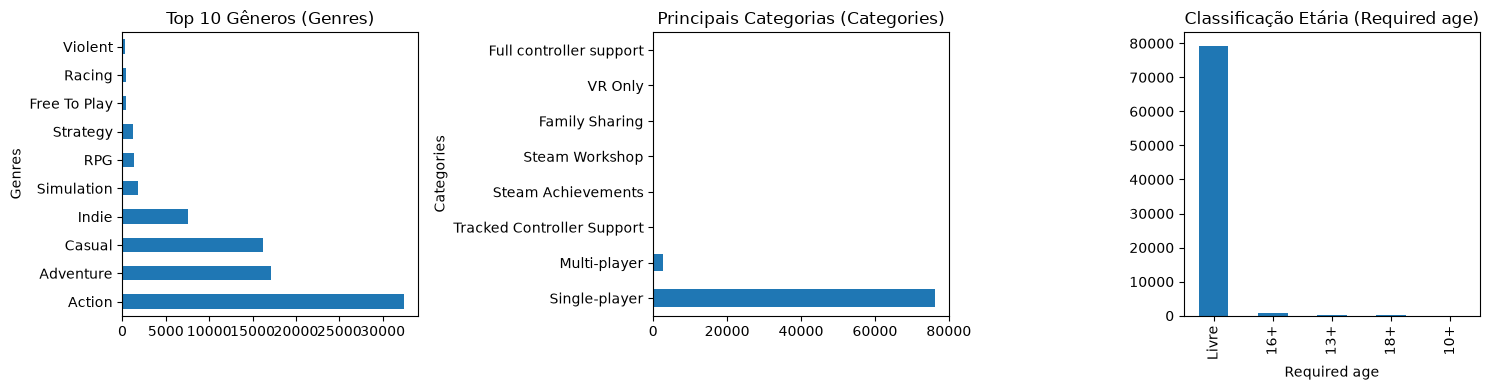

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

X_tr['Genres'].value_counts().head(10).plot(kind='barh', ax=axes[0])
axes[0].set_title('Top 10 Gêneros (Genres)')

X_tr['Categories'].value_counts().head(8).plot(kind='barh', ax=axes[1])
axes[1].set_title('Principais Categorias (Categories)')

X_tr['Required age'].value_counts().plot(kind='bar', ax=axes[2])
axes[2].set_title('Classificação Etária (Required age)')

plt.tight_layout()
plt.show()

**Observação:** `Genres`, `Categories` e `Tags` têm várias categorias com poucos exemplos além das principais (`Action`, `Adventure`, `Casual`, `Indie`, `Single-player`). Já `Required age` tem uma ordem natural de classificação etária (`Livre` até `18+`).
**Decisão:** Usar `OneHotEncoder(handle_unknown="ignore", min_frequency=100)` nas colunas nominais para tratar categorias raras ou novas, e `OrdinalEncoder` em `Required age` seguindo a ordem das faixas.

## 4. O que se relaciona com o alvo?

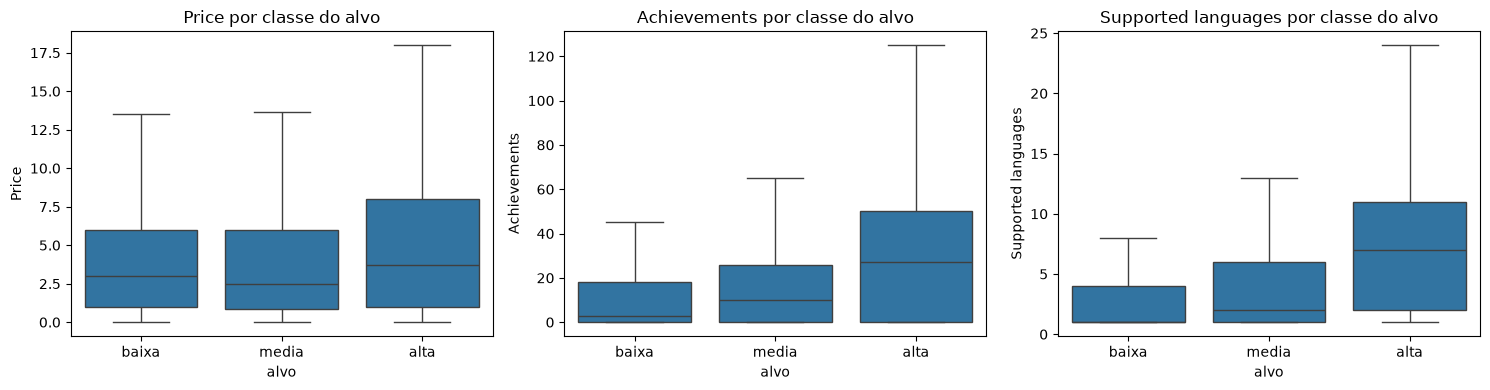

In [7]:
df_treino = X_tr.copy()
df_treino['alvo'] = y_tr

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df_treino, x='alvo', y='Price', order=['baixa', 'media', 'alta'], showfliers=False, ax=axes[0])
axes[0].set_title('Price por classe do alvo')

sns.boxplot(data=df_treino, x='alvo', y='Achievements', order=['baixa', 'media', 'alta'], showfliers=False, ax=axes[1])
axes[1].set_title('Achievements por classe do alvo')

sns.boxplot(data=df_treino, x='alvo', y='Supported languages', order=['baixa', 'media', 'alta'], showfliers=False, ax=axes[2])
axes[2].set_title('Supported languages por classe do alvo')

plt.tight_layout()
plt.show()

**Observação:** Jogos da classe `alta` costumam ter mais conquistas (mediana sobe de 3 na `baixa` para 10 na `media` e 27 na `alta`), suporte a mais idiomas (mediana sobe de 1 para 2 e 7) e preço mediano um pouco maior.
**Decisão:** Manter `Price`, `Achievements` e `Supported languages` no modelo pois ajudam a separar as classes sem vazar informação pós-lançamento.

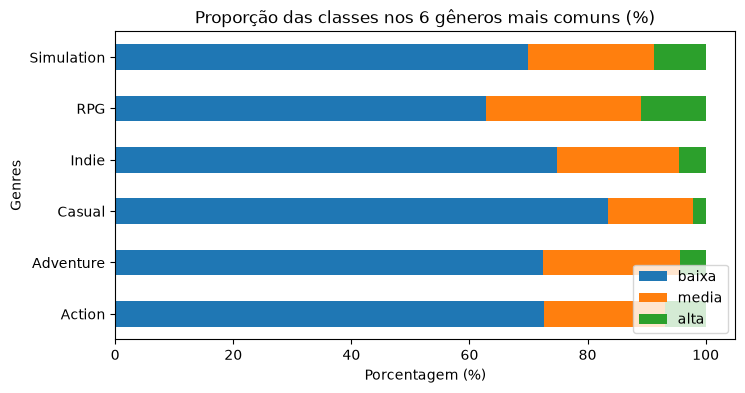

In [8]:
top_generos = df_treino['Genres'].value_counts().head(6).index
tabela_generos = pd.crosstab(df_treino[df_treino['Genres'].isin(top_generos)]['Genres'], df_treino['alvo'], normalize='index')[['baixa', 'media', 'alta']] * 100

tabela_generos.plot(kind='barh', stacked=True, figsize=(8, 4))
plt.title('Proporção das classes nos 6 gêneros mais comuns (%)')
plt.xlabel('Porcentagem (%)')
plt.legend(loc='lower right')
plt.show()

**Observação:** A distribuição do alvo muda conforme o gênero: gêneros como `RPG` e `Simulation` têm uma fatia bem maior de jogos nas faixas `media` e `alta` do que jogos `Casual`.
**Decisão:** Manter as colunas categóricas de perfil do jogo e confirmar a remoção de colunas como `Recommendations`, `Positive`, `Negative` e `Peak CCU` em `limpar(df)` por serem vazamento do alvo.

## 5. Há colunas redundantes?

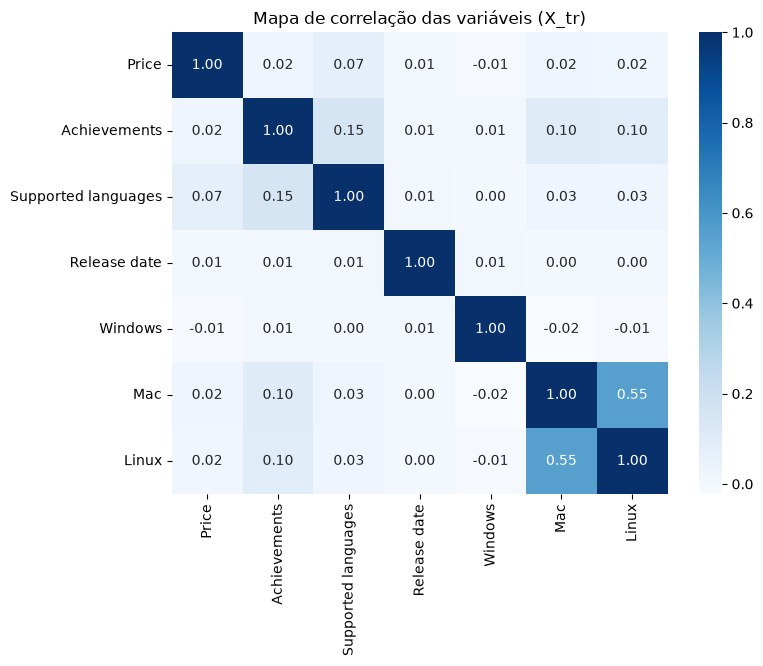

In [9]:
df_corr = X_tr[['Price', 'Achievements', 'Supported languages', 'Release date']].copy()
df_corr['Windows'] = (X_tr['Windows'] == 'True').astype(int)
df_corr['Mac'] = (X_tr['Mac'] == 'True').astype(int)
df_corr['Linux'] = (X_tr['Linux'] == 'True').astype(int)

corr = df_corr.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, cbar=True, fmt='.2f', annot=True, cmap='Blues')
plt.title('Mapa de correlação das variáveis (X_tr)')
plt.show()

**Observação:** A maior correlação é entre `Mac` e `Linux` (0,55), e entre as variáveis numéricas todas as correlações ficam abaixo de 0,15. Nenhuma chega perto de `|r| > 0,9`.
**Decisão:** Nenhuma ação necessária, nenhuma coluna precisa ser removida por redundância.